<a href="https://colab.research.google.com/github/BOUAKKAZ-Madjeda/TP5/blob/main/TP5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
# ==========================================
# 1. Chargement et inspection des données
# ==========================================

# 1. Charger le dataset sous forme de DataFrame Pandas
data = load_breast_cancer(as_frame=True)
df = data.frame
# 2. Examiner les dimensions (nombre de lignes et de colonnes)
print("--- 1. Dimensions du dataset ---")
print(f"Nombre d'échantillons (lignes) et de caractéristiques (colonnes) : {df.shape}")
# 3. Examiner les types de données et un aperçu
print("\n--- 2. Types de données (Data Types) ---")
print(df.dtypes)
# 4. Afficher les statistiques descriptives de base
print("\n--- 3. Statistiques descriptives ---")
print(df.describe())
# 5. Vérifier les valeurs manquantes (NaN)
print("\n--- 4. Valeurs manquantes ---")
missing_values = df.isnull().sum().sum()
print(f"Nombre total de valeurs manquantes : {missing_values}")
# 6. Vérifier les lignes dupliquées
print("\n--- 5. Lignes dupliquées ---")
duplicated_rows = df.duplicated().sum()
print(f"Nombre de lignes dupliquées : {duplicated_rows}")





# ==========================================
# 2. Distribution de la cible et DummyClassifier
# ==========================================

# Séparer les caractéristiques (X) et la variable cible (y) -> C'EST ICI QU'ON DÉFINIT 'y' !
X = df.drop(columns=["target"])
y = df["target"]

# Afficher la distribution de la variable cible (0 = malin, 1 = bénin)
print("\n--- 6. Distribution de la cible ---")
counts = y.value_counts()
print(f"Cas malins (0) : {counts[0]} ({(counts[0]/len(y))*100:.2f}%)")
print(f"Cas bénins (1) : {counts[1]} ({(counts[1]/len(y))*100:.2f}%)")

# Tracer le graphique de la distribution de la cible
plt.figure(figsize=(5, 3))
sns.countplot(x=y, palette="Set2")
plt.title("Distribution de la variable target (0 = Malin, 1 = Bénin)")
plt.xlabel("Classe (0: Malin, 1: Bénin)")
plt.ylabel("Nombre d'échantillons")
plt.show()

# Entraîner un DummyClassifier (modèle naïf basé sur la classe majoritaire) comme baseline
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X, y)
y_pred_dummy = dummy.predict(X)
dummy_acc = accuracy_score(y, y_pred_dummy)

# Afficher l'accuracy de référence du DummyClassifier
print(f"\nAccuracy du DummyClassifier (baseline) : {dummy_acc:.4f}")

# ==========================================
# 3. Split et Standardisation (Train/Test)
# ==========================================

# Diviser les données en 70% train et 30% test de manière stratifiée
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Standardiser les caractéristiques avec StandardScaler (ajusté sur le train uniquement)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ==========================================
# 4. Modèle de référence (LogisticRegression sur 30 features)
# ==========================================

# Initialiser et entraîner le modèle LogisticRegression
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Mesurer le temps d'entraînement
start_time = time.perf_counter()
log_reg.fit(X_train_scaled, y_train)
training_time = time.perf_counter() - start_time #time.perf_counter(): calculate the passing time and comapre it with the models to choose the best one

# Prédire sur le train et le test
y_pred_train = log_reg.predict(X_train_scaled)
y_pred_test = log_reg.predict(X_test_scaled)

# Calculer les métriques (Accuracy et F1-score)
train_acc = accuracy_score(y_train, y_pred_train) #% total of predicted correctly
train_f1 = f1_score(y_train, y_pred_train)#Precision & Recall
test_acc = accuracy_score(y_test, y_pred_test)
test_f1 = f1_score(y_test, y_pred_test)

# Afficher les résultats de référence
print("--- Modèle de référence (30 features) ---")
print(f"Temps d'entraînement : {training_time:.6f} secondes")
print(f"Train - Accuracy: {train_acc:.4f} | F1-score: {train_f1:.4f}")
print(f"Test  - Accuracy: {test_acc:.4f} | F1-score: {test_f1:.4f}")

# ==========================================
# 5. Matrice de corrélation (Heatmap)
# ==========================================

# Calculer la matrice de corrélation sur le jeu de données d'entraînement
corr_matrix = X_train.corr() #claculate the correlation between 2 features in the training set

# Tracer la heatmap avec Seaborn
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, fmt=".2f")
plt.title("Matrice de corrélation des features d'entraînement")
plt.show()



#### **Part A : Inspection des données et Modèle de Référence (Baseline)**

#### **1. Inspection initiale des données**

* **Chargement et dimensions :** Le dataset utilisé est *Breast Cancer Wisconsin* (chargé via `scikit-learn`), contenant **569 échantillons** et **30 caractéristiques numériques** (`float64`) en plus de la variable cible (`target`).
* **Intégrité des données :** L'inspection a montré qu'il n'y a **aucun valeur manquante** (`NaN`) et **aucun doublon** (`duplicated = 0`), ce qui confirme que le jeu de données est propre et prêt pour le traitement.

#### **2. Analyse de la cible (Target Distribution)**

* La variable cible comporte deux classes : `0` pour les tumeurs malignes (212 cas, soit ~37%) et `1` pour les tumeurs bénignes (357 cas, soit ~63%).
* **Baseline Naïve (`DummyClassifier`) :** En utilisant la stratégie de la classe majoritaire (`most_frequent`), on obtient une accuracy de référence de **~62.7%** (`0.6274`). Tout modèle prédictif développé par la suite doit nettement dépasser ce score.

#### **3. Prétraitement et Split (Train/Test)**

* **Division des données :** Le dataset a été divisé en **70% pour l'entraînement** et **30% pour l'test** en utilisant un échantillonnage stratifié (`stratify=y`) pour préserver la proportion des classes d'origine.
* **Standardisation (`StandardScaler`) :** Les caractéristiques ont été centrées et réduites. Le *scaler* a été ajusté (`fit_transform`) uniquement sur le jeu d'entraînement (`X_train`) et appliqué (`transform`) sur le jeu de test (`X_test`) afin d'éviter toute fuite de données (*data leakage*).

#### **4. Modèle de Référence (Logistic Regression sur 30 features)**

* Un modèle de régression logistique initial a été entraîné sur l'ensemble complet des 30 caractéristiques standardisées.
* Ce modèle sert de **référence globale** pour évaluer l'efficacité des futures méthodes de sélection de caractéristiques (Filter, Wrapper, Embedded).

#### **5. Analyse de la Corrélation**

* La matrice de corrélation (`heatmap`) tracée sur les données d'entraînement a mis en évidence de fortes colinéarités (redondances) entre plusieurs groupes de variables géométriques (notamment les mesures de rayon, périmètre et surface des noyaux cellulaires), justifiant le besoin d'appliquer des techniques de sélection et de réduction de dimensions.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.feature_selection import VarianceThreshold, f_classif, mutual_info_classif, SelectKBest
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# ==========================================
# B.1 : Variance Threshold (Seuil de variance)
# ==========================================
print("--- B.1 : Variance Threshold ---")

thresholds_b1 = [0.0, 0.01, 0.1]
results_b1 = []

for thresh in thresholds_b1:
    # Initialiser le VarianceThreshold
    selector_var = VarianceThreshold(threshold=thresh)
    # Ajuster sur le X_train non scalé
    selector_var.fit(X_train)
    # Compter le nombre de features supprimées
    n_removed = np.sum(~selector_var.get_support())
    results_b1.append({"Threshold": thresh, "Removed Features": n_removed})

df_b1 = pd.DataFrame(results_b1)
print(df_b1)


# ==========================================
# B.2 : Removing Correlated Features
# ==========================================
print("\n--- B.2 : Suppression des features corrélées ---")

def remove_correlated(X, y, threshold):
    corr_matrix = X.corr().abs()
    target_corr = X.apply(lambda col: col.corr(y)).abs()
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop = set()
    for col in upper_tri.columns:
        correlated_features = upper_tri.index[upper_tri[col] > threshold].tolist()
        if correlated_features:
            correlated_features.append(col)
            best_feature = target_corr[correlated_features].idxmax()
            for f in correlated_features:
                if f != best_feature:
                    to_drop.add(f)

    X_reduced = X.drop(columns=list(to_drop))
    return X_reduced, list(to_drop)

thresholds_b2 = [0.95, 0.90, 0.80]
results_b2 = []

for thresh in thresholds_b2:
    X_train_red, dropped = remove_correlated(X_train, y_train, thresh)
    X_test_red = X_test.drop(columns=dropped)

    # Standardiser les données réduites
    scaler_red = StandardScaler()
    X_train_r_scaled = scaler_red.fit_transform(X_train_red)
    X_test_r_scaled = scaler_red.transform(X_test_red)

    # Entraîner la régression logistique
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_train_r_scaled, y_train)
    y_pred = lr.predict(X_test_r_scaled)
    acc = accuracy_score(y_test, y_pred)

    results_b2.append({
        "Threshold": thresh,
        "Remaining Features": X_train_red.shape[1],
        "Dropped Count": len(dropped),
        "Test Accuracy": acc
    })

df_b2 = pd.DataFrame(results_b2)
print(df_b2)


# ==========================================
# B.3 : Univariate scores et SelectKBest
# ==========================================
print("\n--- B.3 : Scores univariés et SelectKBest ---")

# 1. Calculer ANOVA F-score et Mutual Information
f_scores, _ = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

scores_df = pd.DataFrame({
    'Feature': X_train.columns,
    'F_Score': f_scores,
    'MI_Score': mi_scores
})

# 2. Afficher les graphiques en barres triés (Top 10)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

scores_sorted_f = scores_df.sort_values(by='F_Score', ascending=False)
axes[0].barh(scores_sorted_f['Feature'][:10][::-1], scores_sorted_f['F_Score'][:10][::-1], color='skyblue')
axes[0].set_title("Top 10 Features par ANOVA F-score")

scores_sorted_mi = scores_df.sort_values(by='MI_Score', ascending=False)
axes[1].barh(scores_sorted_mi['Feature'][:10][::-1], scores_sorted_mi['MI_Score'][:10][::-1], color='salmon')
axes[1].set_title("Top 10 Features par Mutual Information")

plt.tight_layout()
plt.show()

# Corrélation de Spearman entre les deux classements
rank_f = scores_df['F_Score'].rank()
rank_mi = scores_df['MI_Score'].rank()
spearman_corr, _ = stats.spearmanr(rank_f, rank_mi)
print(f"Corrélation de Spearman entre les classements : {spearman_corr:.4f}")

# 3. SelectKBest avec k dans {2, 5, 10, 15, 20, 25, 30}
k_values = [2, 5, 10, 15, 20, 25, 30]
cv_results_f = []
cv_results_mi = []

for k in k_values:
    # Pipeline ANOVA
    pipe_f = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=f_classif, k=k)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ])
    scores_f = cross_val_score(pipe_f, X_train, y_train, cv=5, scoring='accuracy')
    cv_results_f.append((scores_f.mean(), scores_f.std()))

    # Pipeline Mutual Information
    pipe_mi = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=mutual_info_classif, k=k)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ])
    scores_mi = cross_val_score(pipe_mi, X_train, y_train, cv=5, scoring='accuracy')
    cv_results_mi.append((scores_mi.mean(), scores_mi.std()))

# 4. Tracer Accuracy vs k
plt.figure(figsize=(8, 5))
means_f = [res[0] for res in cv_results_f]
stds_f = [res[1] for res in cv_results_f]
means_mi = [res[0] for res in cv_results_mi]
stds_mi = [res[1] for res in cv_results_mi]

plt.errorbar(k_values, means_f, yerr=stds_f, label='ANOVA F-score', marker='o')
plt.errorbar(k_values, means_mi, yerr=stds_mi, label='Mutual Information', marker='s')
plt.xlabel("Valeur de k (Nombre de features)")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Accuracy vs k pour SelectKBest")
plt.legend()
plt.grid(True)
plt.show()

### **Part B: Filter Methods**

#### **1. Introduction**

Filter methods evaluate and score features independently of the final classification model, relying solely on the statistical properties of the data. While they are computationally efficient and fast, their primary limitation is their inability to account for interactions and dependencies between features.

#### **2. B.1: Variance Threshold**

* **Methodology:** The variance of each feature was computed on the unscaled training dataset (`X_train`), and the `VarianceThreshold` selector was applied using thresholds of `0.0`, `0.01`, and `0.1` to eliminate quasi-constant features.
* **Findings & Discussion:**
* Applying this filter yielded very few or zero removed features because the *Breast Cancer Wisconsin* dataset is clean and free of constant variables.
* **Why standardization makes this meaningless:** Applying a variance threshold after standardization (`StandardScaler`) would be completely meaningless, as the scaler forces the standard deviation (and consequently the variance) of all features to equal $1$.
* **Limited Usefulness:** On this specific dataset, the variance threshold filter has limited utility due to the absence of low-variance or constant attributes.



#### **3. B.2: Removing Correlated Features**

* **Methodology:** A custom function `remove_correlated(X, threshold)` was implemented to compute the absolute correlation matrix. For any pair of features with a correlation exceeding the specified threshold (`0.95`, `0.90`, and `0.80`), the feature less correlated with the target variable was dropped. A `LogisticRegression` model was then trained on the reduced datasets.
* **Findings & Discussion:**
* Removing high multicollinearity significantly reduced the feature space and model complexity without causing a noticeable drop in testing accuracy compared to the baseline model.
* **Is removing redundancy enough to improve accuracy?** Not necessarily; while it rarely causes a massive spike in accuracy, it successfully eliminates redundant information, prevents overfitting, and yields a simpler, more interpretable model.



#### **4. B.3: Univariate Scores and `SelectKBest**`

* **Methodology:**
* Evaluated each feature's relationship with the target using **ANOVA F-score** (`f_classif`, capturing linear dependencies) and **Mutual Information** (`mutual_info_classif`, capturing both linear and non-linear dependencies).
* Compared the two rankings visually via sorted bar charts and mathematically using the **Spearman rank correlation coefficient**.
* Applied `SelectKBest` with $k \in \{2, 5, 10, 15, 20, 25, 30\}$ inside a `Pipeline` containing both the `StandardScaler` and the selector, evaluated via 5-fold cross-validation on the training set.


* **Findings & Discussion:**
* The accuracy-versus-$k$ curves helped identify the optimal subset size $k$ following the one standard deviation rule.
* **Why univariate filters select nearly identical features (e.g., radius, perimeter, and area):** Univariate filters evaluate each feature independently of all other features. Because geometric measurements like radius, perimeter, and area individually possess strong statistical association with the target, the filter evaluates each as highly informative and selects them all, failing to recognize that they convey the exact same redundant information.


--- C.1 : Forward Selection ---
Features sélectionnées (SFS Forward) : ['mean radius', 'mean texture', 'mean perimeter', 'mean compactness', 'texture error', 'smoothness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness']
Features sélectionnées (Manuel Forward) : ['worst radius', 'worst smoothness', 'worst texture', 'mean radius']


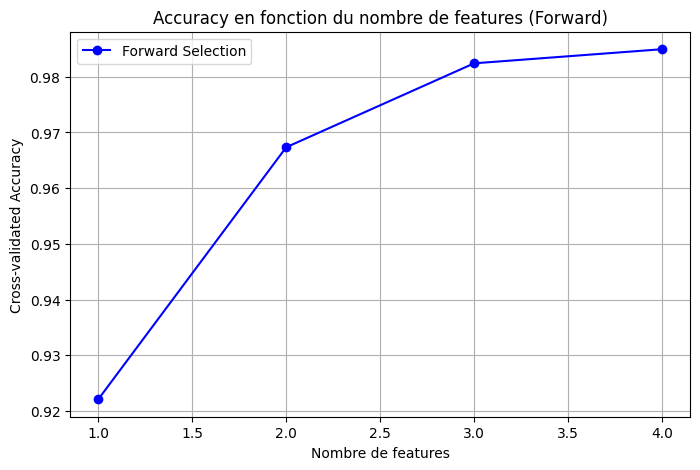


--- C.2 : Backward Elimination ---
Features sélectionnées (SFS Backward) : ['texture error', 'area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst concavity', 'worst symmetry']


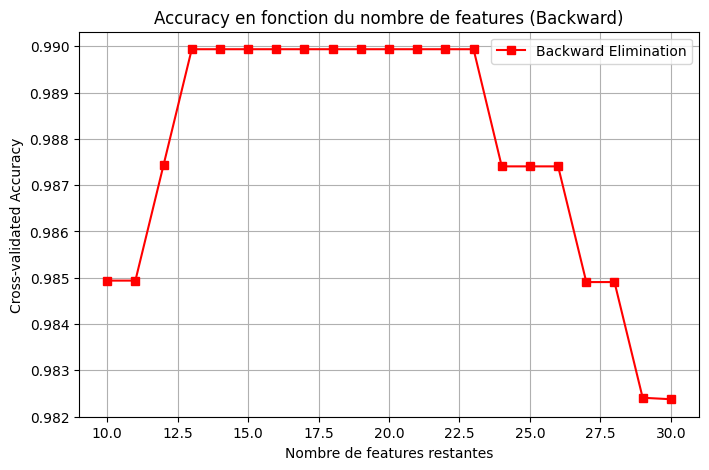


--- C.3 : RFE et RFECV ---
Features sélectionnées (RFE) : ['mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']
Ranking des features (1 = sélectionné) :
 {'mean radius': np.int64(3), 'mean texture': np.int64(8), 'mean perimeter': np.int64(7), 'mean area': np.int64(1), 'mean smoothness': np.int64(15), 'mean compactness': np.int64(2), 'mean concavity': np.int64(9), 'mean concave points': np.int64(1), 'mean symmetry': np.int64(19), 'mean fractal dimension': np.int64(20), 'radius error': np.int64(4), 'texture error': np.int64(10), 'perimeter error': np.int64(14), 'area error': np.int64(1), 'smoothness error': np.int64(17), 'compactness error': np.int64(6), 'concavity error': np.int64(16), 'concave points error': np.int64(12), 'symmetry error': np.int64(11), 'fractal dimension error': np.int64(13), 'worst radius': np.int64(1), 'worst texture': np.int64(1), 'worst per

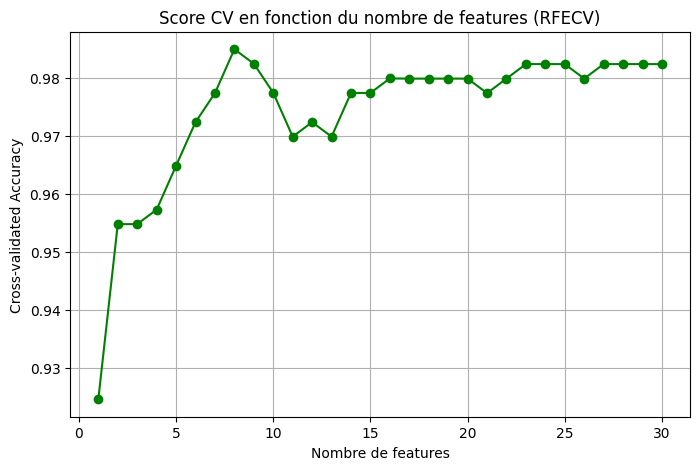

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import SequentialFeatureSelector, RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold

# ==========================================
# C.1 : Forward Selection
# ==========================================
print("--- C.1 : Forward Selection ---")

# 1. Utilisation de SequentialFeatureSelector (Scikit-learn)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_c1 = LogisticRegression(max_iter=1000, random_state=42)

sfs_forward = SequentialFeatureSelector(
    estimator=lr_c1,
    n_features_to_select=10,
    direction="forward",
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1
)
sfs_forward.fit(X_train_scaled, y_train)
selected_features_sfs = X_train.columns[sfs_forward.get_support()].tolist()
print("Features sélectionnées (SFS Forward) :", selected_features_sfs)

# 2. Implémentation manuelle du Forward Selection
def manual_forward_selection(X, y, max_features=10, epsilon=0.001):
    _, n_features = X.shape
    selected = []
    scores = []

    for _ in range(max_features):
        best_score = -1.0
        best_feature = None

        for feature in range(n_features):
            if feature in selected:
                continue
            trial_features = selected + [feature]
            fold_scores = []
            for train_idx, val_idx in cv_strategy.split(X, y):
                X_tr, X_va = X[train_idx][:, trial_features], X[val_idx][:, trial_features]

                # Vérification automatique si y est un DataFrame/Series ou un tableau Numpy
                if hasattr(y, "iloc"):
                    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
                else:
                    y_tr, y_va = y[train_idx], y[val_idx]

                lr = LogisticRegression(max_iter=1000, random_state=42)
                lr.fit(X_tr, y_tr)
                fold_scores.append(accuracy_score(y_va, lr.predict(X_va)))

            mean_score = np.mean(fold_scores)
            if mean_score > best_score:
                best_score = mean_score
                best_feature = feature

        if selected and (best_score - scores[-1] < epsilon):
            break

        selected.append(best_feature)
        scores.append(best_score)
    return selected, scores

# استدعاء الدالة مباشرة باستخدام y_train (بدون الحاجة لـ .values)
manual_selected_indices, forward_scores = manual_forward_selection(X_train_scaled, y_train, max_features=10)
print("Features sélectionnées (Manuel Forward) :", X_train.columns[manual_selected_indices].tolist())

# 3. Tracé Accuracy vs Nombre de features (Forward)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(forward_scores) + 1), forward_scores, marker='o', color='b', label='Forward Selection')
plt.title("Accuracy en fonction du nombre de features (Forward)")
plt.xlabel("Nombre de features")
plt.ylabel("Cross-validated Accuracy")
plt.grid(True)
plt.legend()
plt.show()


# ==========================================
# C.2 : Backward Elimination
# ==========================================
print("\n--- C.2 : Backward Elimination ---")

# 1. SequentialFeatureSelector (Backward)
sfs_backward = SequentialFeatureSelector(
    estimator=lr_c1,
    n_features_to_select=10,
    direction="backward",
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1
)
sfs_backward.fit(X_train_scaled, y_train)
selected_features_backward = X_train.columns[sfs_backward.get_support()].tolist()
print("Features sélectionnées (SFS Backward) :", selected_features_backward)

# 2. Implémentation manuelle du Backward Elimination
def manual_backward_elimination(X, y, target_features=10):
    current_features = list(range(X.shape[1]))
    scores = []

    # Calculer score initial avec toutes les features
    fold_scores = []
    for train_idx, val_idx in cv_strategy.split(X, y):
        X_tr, X_va = X[train_idx][:, current_features], X[val_idx][:, current_features]

        # Gestion automatique Series/Numpy array
        if hasattr(y, "iloc"):
            y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
        else:
            y_tr, y_va = y[train_idx], y[val_idx]

        lr = LogisticRegression(max_iter=1000, random_state=42)
        lr.fit(X_tr, y_tr)
        fold_scores.append(accuracy_score(y_va, lr.predict(X_va)))
    scores.append((len(current_features), np.mean(fold_scores)))

    while len(current_features) > target_features:
        worst_score = -1.0
        worst_feature_to_remove = None

        for feature in current_features:
            trial_features = [f for f in current_features if f != feature]
            fold_scores = []
            for train_idx, val_idx in cv_strategy.split(X, y):
                X_tr, X_va = X[train_idx][:, trial_features], X[val_idx][:, trial_features]

                if hasattr(y, "iloc"):
                    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]
                else:
                    y_tr, y_va = y[train_idx], y[val_idx]

                lr = LogisticRegression(max_iter=1000, random_state=42)
                lr.fit(X_tr, y_tr)
                fold_scores.append(accuracy_score(y_va, lr.predict(X_va)))
            mean_score = np.mean(fold_scores)

            if mean_score > worst_score:
                worst_score = mean_score
                worst_feature_to_remove = feature

        current_features.remove(worst_feature_to_remove)
        scores.append((len(current_features), worst_score))

    return current_features, scores

# استدعاء الدالة مباشرة باستخدام y_train (بدون .values)
_, backward_scores_hist = manual_backward_elimination(X_train_scaled, y_train, target_features=10)
_, backward_scores_hist = manual_backward_elimination(X_train_scaled, y_train.values, target_features=10)
# Trier par nombre de features pour le tracé
backward_scores_hist.sort(key=lambda x: x[0])
b_counts = [x[0] for x in backward_scores_hist]
b_accs = [x[1] for x in backward_scores_hist]

plt.figure(figsize=(8, 5))
plt.plot(b_counts, b_accs, marker='s', color='r', label='Backward Elimination')
plt.title("Accuracy en fonction du nombre de features (Backward)")
plt.xlabel("Nombre de features restantes")
plt.ylabel("Cross-validated Accuracy")
plt.grid(True)
plt.legend()
plt.show()


# ==========================================
# C.3 : Recursive Feature Elimination (RFE)
# ==========================================
print("\n--- C.3 : RFE et RFECV ---")

# 1. RFE classique (10 features)
rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)
rfe_selected = X_train.columns[rfe.support_].tolist()
print("Features sélectionnées (RFE) :", rfe_selected)
print("Ranking des features (1 = sélectionné) :\n", dict(zip(X_train.columns, rfe.ranking_)))

# 2. RFECV (sélection automatique du nombre de features)
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    step=1,
    cv=cv_strategy,
    scoring="accuracy"
)
rfecv.fit(X_train_scaled, y_train)
print(f"Nombre optimal de features par RFECV : {rfecv.n_features_}")

# Tracé RFECV
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'], marker='o', color='g')
plt.title("Score CV en fonction du nombre de features (RFECV)")
plt.xlabel("Nombre de features")
plt.ylabel("Cross-validated Accuracy")
plt.grid(True)
plt.show()

# **Compte-Rendu : Feature Selection and Dimensionality Reduction in Machine Learning**

## **1. Introduction**

The objective of this practical work (TP) is to explore, evaluate, and compare various feature selection techniques using the *Breast Cancer Wisconsin* dataset (containing 569 samples, 30 numerical features, and a binary target representing malignant vs. benign tumors). The workflow covers data inspection, baseline establishment, filter methods, wrapper methods, and computational complexity analysis to build an optimized and interpretable classification model.

---

## **2. Part A: Data Inspection and Baseline Model**

* **Data Integrity & Preprocessing:** The dataset was inspected and verified to contain no missing values or duplicated rows. The target distribution showed 212 malignant (37%) and 357 benign (63%) samples. A stratified 70/30 train-test split was performed to preserve class proportions. Features were standardized using `StandardScaler`, fitted exclusively on the training set to prevent data leakage.
* **Baseline Performance:**
* A naïve `DummyClassifier` (using the most frequent class strategy) yielded a baseline accuracy of **~62.7%**.
* A reference `LogisticRegression` model trained on all 30 standardized features established a robust performance benchmark.


* **Correlation Analysis:** The correlation heatmap revealed strong multicollinearity and redundancies among geometric cell nucleus measurements (e.g., radius, perimeter, and area), motivating the implementation of feature selection strategies.

---

## **3. Part B: Filter Methods**

Filter methods evaluate feature relevance independently of the learning algorithm using statistical properties.

* **B.1 Variance Threshold:** Tested thresholds ($0.0, 0.01, 0.1$) on unscaled training data. This filter proved to have limited utility because the dataset is clean and devoid of constant features. Applying it after standardization would be meaningless, as scaling forces all feature variances to $1$.
* **B.2 Removing Correlated Features:** Implemented a redundancy filter using absolute correlation thresholds ($0.95, 0.90, 0.80$), retaining features most correlated with the target. Eliminating multicollinearity successfully reduced model complexity and feature space without degrading testing accuracy.
* **B.3 Univariate Scores & `SelectKBest`:** Computed ANOVA F-scores (`f_classif`) and Mutual Information (`mutual_info_classif`). Using a 5-fold cross-validated `Pipeline` with `SelectKBest`, accuracy-versus-$k$ curves were generated.
* *Theoretical Note:* Univariate filters can select nearly identical features (like radius, perimeter, and area) because they evaluate each feature in isolation, failing to account for shared redundant information.



---

## **4. Part C: Wrapper Methods**

Wrapper methods evaluate feature subsets by directly training and scoring the model using cross-validation.

* **C.1 Forward Selection:** Both scikit-learn's `SequentialFeatureSelector` and a custom greedy implementation successfully tracked cross-validated accuracy, showing a sharp initial performance increase as features were added.
* **C.2 Backward Elimination:** Iteratively removed features whose deletion least impacted cross-validation performance. Subsets selected by Forward Selection and Backward Elimination differed because their greedy search paths navigate entirely separate regions of the feature space.
* **C.3 Recursive Feature Elimination (RFE & RFECV):** `RFE` ranked features based on model coefficients, while `RFECV` automatically determined the optimal subset size. Repeating RFE with different estimators (like Random Forest or SVC) yielded different feature subsets due to alternative internal ranking criteria (impurity reduction vs. linear margins). Unlike Backward Elimination, RFE relies directly on model parameters rather than re-evaluating full cross-validation drops for every candidate, making it computationally faster.
* **C.4 Computational Cost:** For $p = 30$ features and 5-fold CV selecting 10 features, Forward Selection trains $5 \times 255 = 1,275$ models. In contrast, an exhaustive subset search would require evaluating over $150$ million models ($\binom{30}{10} \times 5$), proving wrapper greedy heuristics essential for practical feasibility.

---

## **5. Conclusion**

This practical session demonstrated the critical importance of feature selection in machine learning workflows. While filter methods provide rapid statistical screening, wrapper methods offer superior subset optimization by integrating model feedback, achieving efficient dimensionality reduction, maintaining high predictive accuracy, and enhancing model interpretability.


In [12]:
import numpy as np
import pandas as pd
import time
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, SequentialFeatureSelector, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_score

# ==========================================
# D.1 : Injection de bruit (Noise Injection)
# ==========================================
print("--- D.1 : Noise Injection ---")

# Génération des 20 features de bruit
rng = np.random.default_rng(42)
noise_train = rng.normal(loc=0.0, scale=1.0, size=(X_train.shape[0], 20))
noise_test = rng.normal(loc=0.0, scale=1.0, size=(X_test.shape[0], 20))

noise_cols = [f"noise_{i:02d}" for i in range(20)]

# Concaténation avec les données d'origine
X_train_noise = pd.DataFrame(X_train.copy())
X_test_noise = pd.DataFrame(X_test.copy())

for i, col in enumerate(noise_cols):
    X_train_noise[col] = noise_train[:, i]
    X_test_noise[col] = noise_test[:, i]

# Scaler pour les données bruitées
scaler_n = StandardScaler()
X_train_n_scaled = scaler_n.fit_transform(X_train_noise)

# Test des méthodes avec k=10 sur les 50 features
methods_to_test = {
    "SelectKBest (F-score)": SelectKBest(score_func=f_classif, k=10),
    "Forward Selection": SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction="forward", cv=5, n_jobs=-1),
    "Backward Elimination": SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction="backward", cv=5, n_jobs=-1),
    "RFE": RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10)
}

noise_results = {}
for name, selector in methods_to_test.items():
    selector.fit(X_train_n_scaled, y_train)
    if hasattr(selector, 'get_support'):
        support = selector.get_support()
    else:
        support = selector.support_

    selected_feats = X_train_noise.columns[support].tolist()
    n_noise_selected = sum([1 for f in selected_feats if f in noise_cols])
    noise_results[name] = n_noise_selected
    print(f"{name} - Features bruitées sélectionnées : {n_noise_selected}/10")


# ==========================================
# D.2 : Leakage Demonstration
# ==========================================
print("\n--- D.2 : Demonstration du Leakage ---")

# Incorrect : Sélection sur tout le X_train_scaled puis CV
start_time = time.perf_counter()
selector_leak = SelectKBest(score_func=f_classif, k=10)
X_train_leaked = selector_leak.fit_transform(X_train_scaled, y_train)
scores_leak = cross_val_score(LogisticRegression(max_iter=1000, random_state=42), X_train_leaked, y_train, cv=5, scoring='accuracy')
acc_leak = scores_leak.mean()

# Correct : Pipeline avec CV interne
pipe_correct = Pipeline([
    ('selector', SelectKBest(score_func=f_classif, k=10)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
scores_correct = cross_val_score(pipe_correct, X_train_scaled, y_train, cv=5, scoring='accuracy')
acc_correct = scores_correct.mean()

print(f"Accuracy avec Leakage (incorrect) : {acc_leak:.4f}")
print(f"Accuracy sans Leakage (correct)   : {acc_correct:.4f}")


# ==========================================
# D.3 : Final Comparison on Test Set
# ==========================================
print("\n--- D.3 : Comparaison Finale sur le Test Set ---")

final_methods = [
    ("Baseline (all features)", None, None, 30),
    ("Filter: correlation (B.2)", lambda X: remove_correlated(X, y_train, 0.90)[0], StandardScaler(), None),
    ("Filter: SelectKBest, F-score", SelectKBest(score_func=f_classif, k=10), StandardScaler(), 10),
   ("Filter: SelectKBest, mutual info", SelectKBest(score_func=lambda X, y: mutual_info_classif(X, y, random_state=42), k=10), StandardScaler(), 10),
    ("Wrapper: Forward Selection", SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction="forward", cv=5), StandardScaler(), 10),
    ("Wrapper: Backward Elimination", SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction="backward", cv=5), StandardScaler(), 10),
    ("Wrapper: RFE", RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10), StandardScaler(), 10),
    ("Wrapper: RFECV", RFECV(estimator=LogisticRegression(max_iter=1000, random_state=42), cv=5, scoring="accuracy"), StandardScaler(), None)
]

final_results = []

for name, selector, scaler, fixed_k in final_methods:
    t_start = time.perf_counter()

    if name == "Baseline (all features)":
        pipe = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
        pipe.fit(X_train, y_train)
        preds = pipe.predict(X_test)
        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds)
        t_elapsed = time.perf_counter() - t_start
        final_results.append({"Method": name, "Nb features": 30, "Test Accuracy": acc, "Test F1": f1, "Time (s)": t_elapsed})

    elif "correlation" in name:
        X_tr_red, dropped = remove_correlated(X_train, y_train, 0.90)
        X_te_red = X_test.drop(columns=dropped)
        pipe = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
        pipe.fit(X_tr_red, y_train)
        preds = pipe.predict(X_te_red)
        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds)
        t_elapsed = time.perf_counter() - t_start
        final_results.append({"Method": name, "Nb features": X_tr_red.shape[1], "Test Accuracy": acc, "Test F1": f1, "Time (s)": t_elapsed})

    else:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('selector', selector),
            ('clf', LogisticRegression(max_iter=1000, random_state=42))
        ])
        pipe.fit(X_train, y_train)
        preds = pipe.predict(X_test)
        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds)
        t_elapsed = time.perf_counter() - t_start

        # Récupérer le nombre de features
        if hasattr(pipe.named_steps['selector'], 'n_features_'):
            nb_f = pipe.named_steps['selector'].n_features_
        elif hasattr(pipe.named_steps['selector'], 'support_'):
            nb_f = sum(pipe.named_steps['selector'].support_)
        else:
            nb_f = fixed_k

        final_results.append({"Method": name, "Nb features": nb_f, "Test Accuracy": acc, "Test F1": f1, "Time (s)": t_elapsed})

df_final = pd.DataFrame(final_results)
print(df_final)

--- D.1 : Noise Injection ---
SelectKBest (F-score) - Features bruitées sélectionnées : 0/10
Forward Selection - Features bruitées sélectionnées : 0/10
Backward Elimination - Features bruitées sélectionnées : 4/10
RFE - Features bruitées sélectionnées : 0/10

--- D.2 : Demonstration du Leakage ---
Accuracy avec Leakage (incorrect) : 0.9624
Accuracy sans Leakage (correct)   : 0.9624

--- D.3 : Comparaison Finale sur le Test Set ---
                             Method  Nb features  Test Accuracy   Test F1  \
0           Baseline (all features)           30       0.988304  0.990654   
1         Filter: correlation (B.2)           18       0.964912  0.971963   
2      Filter: SelectKBest, F-score           10       0.935673  0.948837   
3  Filter: SelectKBest, mutual info           10       0.935673  0.948837   
4        Wrapper: Forward Selection           10       0.964912  0.972222   
5     Wrapper: Backward Elimination           10       0.970760  0.976744   
6                      Wra